# Step 4 - Evaluation on simulations and on real data

This notebook reads the outputs of:

* `scripts/08_evaluate_simulations.py`: simulation benchmark per class, SNR and event sub-group;
* `scripts/09_ml_frequency_check.py`: does the ML detector rely on a simulator artefact (`freq_hz`)?
* `scripts/10_evaluate_real.py`: leave-one-patient-out on the real fast-ripple markings;
* `scripts/11_real_fr_context.py`: how many real fast ripples ride on a spike.

No threshold or model ever sees its test data. All intervals are 95 % percentile bootstrap intervals over independent units: simulated channels or patients.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from epidetect.config import load_config

cfg = load_config()
R, F = cfg["paths"]["results_dir"], cfg["paths"]["figures_dir"]
pd.set_option("display.width", 180)
def fmt(df):
    return df.assign(value=df.apply(lambda r: f"{r.estimate:.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}]", axis=1))

## 1. Why accuracy is meaningless here

Fraction of recording time covered by the reference fast ripples (pre-resection, analysed channels). A detector that never detects anything would be 'right' almost all the time.

In [2]:
per_patient = pd.read_csv(R / "real_lopo_per_patient.csv", dtype={"patient": str})
one = per_patient[(per_patient.analysis == "all channels") & (per_patient.strategy == "A") & (per_patient.detector == "energy")]
bids = cfg["paths"]["bids_root"]
fr_seconds = sum(pd.read_csv(f, sep="\t")["duration"].sum() for p in one.patient
                 for f in (bids / f"sub-{p}" / "ses-preresection" / "ieeg").glob("*_events.tsv"))
total_seconds = one.minutes.sum() * 60
print(f"FR time: {fr_seconds:.1f} s out of {total_seconds/3600:.1f} channel-hours = {100*fr_seconds/total_seconds:.3f} %")
print(f"'Never detect' accuracy (sample level): {100*(1 - fr_seconds/total_seconds):.3f} %")

FR time: 47.2 s out of 16.6 channel-hours = 0.079 %
'Never detect' accuracy (sample level): 99.921 %


## 2. Simulation benchmark

### 2.1 Thresholds chosen on the training simulations

In [3]:
pd.read_csv(R / "sim_tuned_thresholds.csv").round(3)

,band,energy_k,wavelet_z,ml_threshold,train_f1_energy,train_f1_wavelet,train_f1_ml
0,ripple,2.5,6.0,0.45,0.491,0.709,0.650
1,fast_ripple,3.5,6.0,0.40,0.572,0.647,0.703


### 2.2 Metrics at 10 dB (95 % CI over 10 test channels)

In [4]:
sim = pd.read_csv(R / "sim_eval_metrics.csv")
keep = ["f1", "precision", "recall_isolated", "recall_on_spike", "spike_false_alarm_rate"]
t = fmt(sim[(sim.snr_db == 10) & sim.metric.isin(keep)])
t.pivot_table(index=["band", "detector"], columns="metric", values="value", aggfunc="first")[keep]

metric                               f1          precision    recall_isolated    recall_on_spike spike_false_alarm_rate
band        detector                                                                                                   
fast_ripple energy    0.68 [0.64, 0.72]  0.61 [0.55, 0.68]  0.72 [0.65, 0.79]  0.88 [0.81, 0.96]      0.25 [0.18, 0.32]
            ml        0.87 [0.82, 0.92]  0.89 [0.82, 0.95]  0.99 [0.97, 1.00]  0.52 [0.36, 0.71]      0.00 [0.00, 0.00]
            wavelet   0.81 [0.76, 0.86]  0.92 [0.88, 0.96]  0.98 [0.95, 1.00]  0.09 [0.00, 0.26]      0.00 [0.00, 0.00]
ripple      energy    0.50 [0.44, 0.56]  0.37 [0.30, 0.42]  0.71 [0.62, 0.80]  1.00 [1.00, 1.00]      1.00 [1.00, 1.00]
            ml        0.75 [0.70, 0.80]  0.81 [0.73, 0.89]  0.95 [0.89, 1.00]  0.19 [0.06, 0.32]      0.13 [0.07, 0.19]
            wavelet   0.78 [0.71, 0.81]  0.96 [0.89, 1.00]  0.97 [0.93, 1.00]  0.00 [0.00, 0.00]      0.01 [0.00, 0.03]

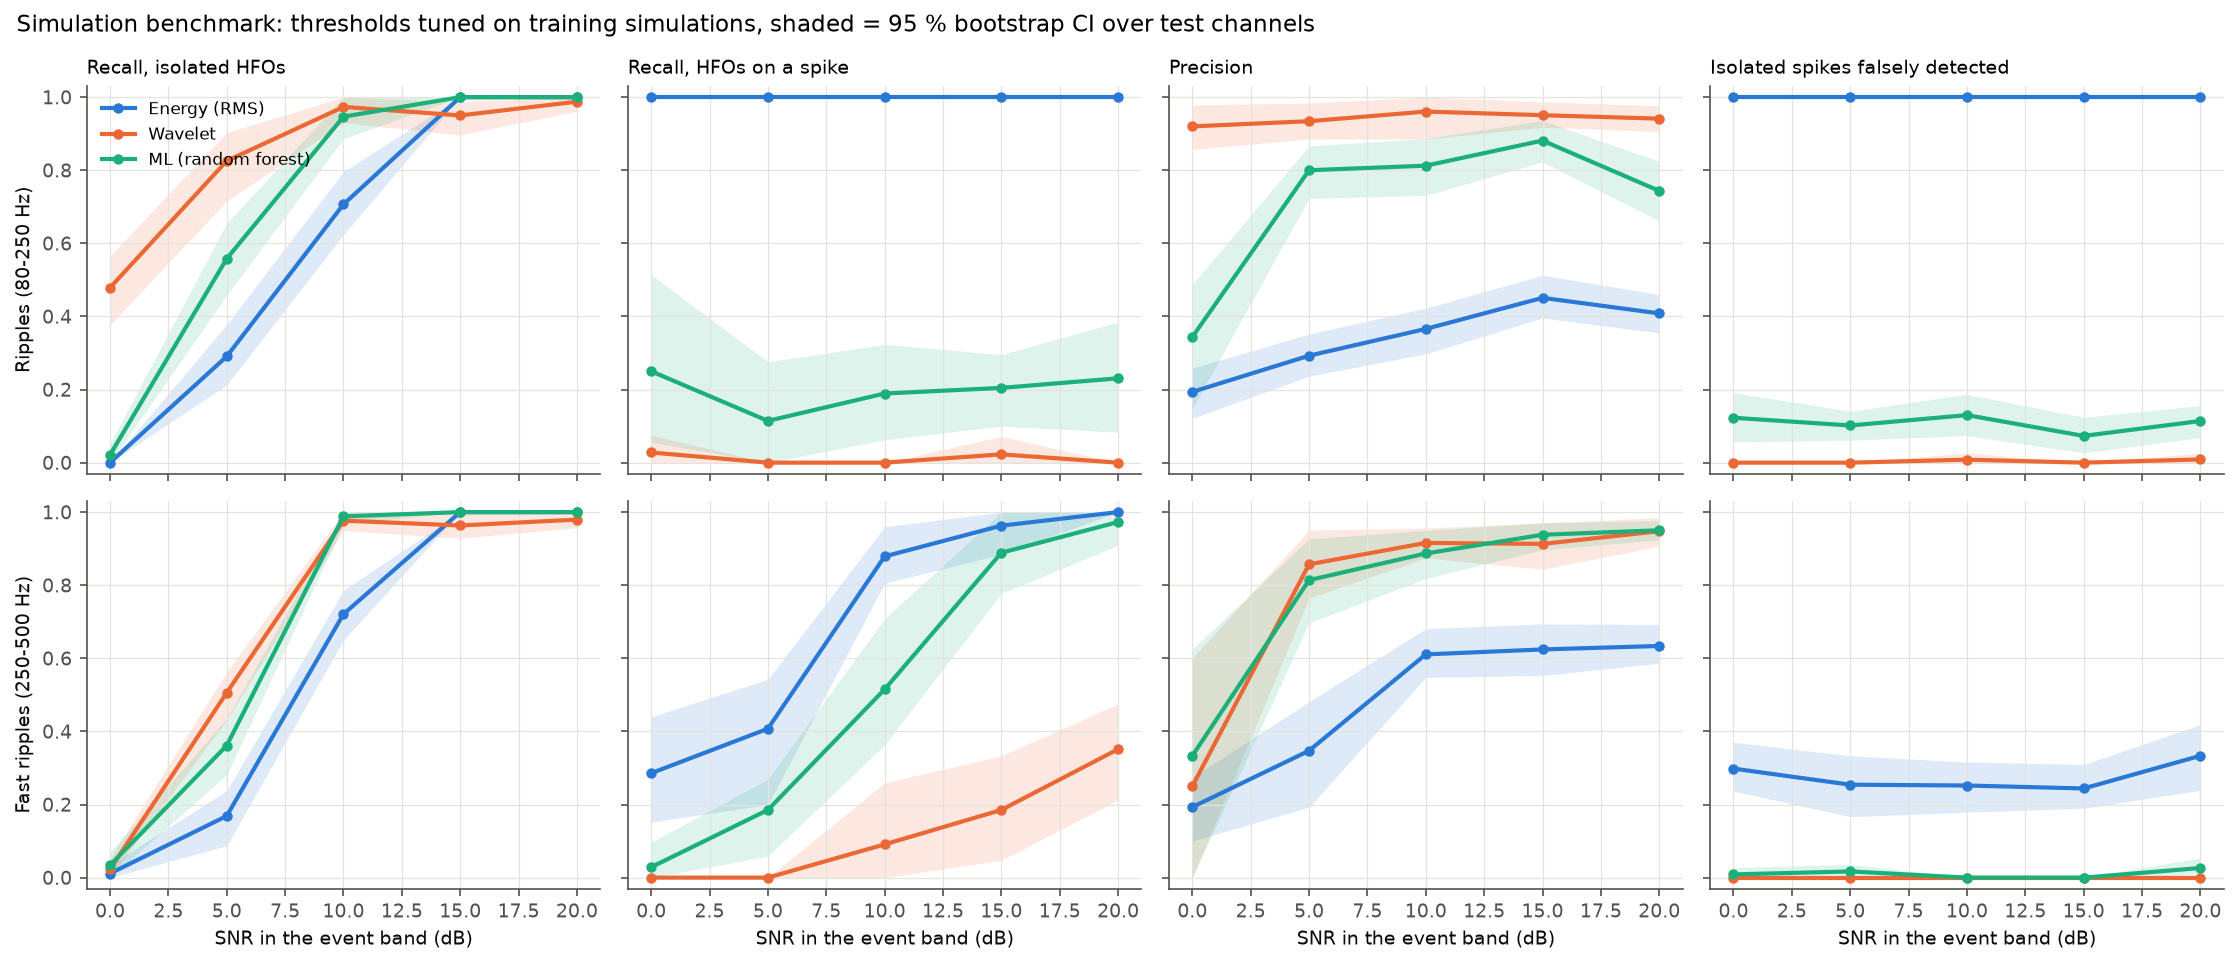

In [5]:
display(Image(filename=str(F / "sim_benchmark_snr.png")))

Reading the figure:

* **Energy**: every isolated spike gives a ripple-band detection, and its 100 % recall on ripples riding on spikes is triggered by the spike, not by the oscillation.
* **Wavelet**: best precision and almost no false alarm on spikes, but it misses HFOs on spikes.
* **ML**: best fast-ripple F1 from 10 dB, and it recovers HFOs on spikes when the SNR increases.
* SNR is defined over the whole band: with a steep 1/f background, a ripple at 0 dB is locally strong, which favours the wavelet detector in the ripple band (see README limitations).

## 3. Does the ML detector depend on a simulator artefact?

In [6]:
pd.read_csv(R / "frequency_distributions.csv", index_col=0)

,q10,q25,q50,q75,q90,n
real fast ripples,272.7,285.7,303.0,324.3,346.7,2378
real transients (ringing),292.7,317.1,341.5,365.9,390.2,3000
simulated fast ripples (uniform),278.2,291.8,381.6,437.2,471.8,59
simulated spikes (ringing),243.9,243.9,268.3,292.7,341.5,64


In [7]:
fc = pd.read_csv(R / "ml_frequency_check.csv")
fmt(fc[fc.metric == "f1"]).pivot_table(index=["test_set", "variant"], columns="snr_db", values="value", aggfunc="first")

snr_db                                                             0.0                5.0                10.0               15.0               20.0
test_set  variant                                                                                                                                  
realistic A: uniform training, all features           0.08 [0.02, 0.15]  0.50 [0.42, 0.57]  0.86 [0.80, 0.91]  0.94 [0.91, 0.97]  0.97 [0.94, 0.99]
          B: uniform training, no freq_hz             0.09 [0.03, 0.16]  0.48 [0.41, 0.56]  0.87 [0.81, 0.92]  0.92 [0.88, 0.96]  0.99 [0.96, 1.00]
          C: uniform training, no freq_hz / n_cycles  0.14 [0.08, 0.20]  0.54 [0.47, 0.59]  0.85 [0.79, 0.90]  0.90 [0.85, 0.94]  0.95 [0.93, 0.98]
          D: realistic training, all features         0.06 [0.01, 0.13]  0.59 [0.52, 0.64]  0.89 [0.85, 0.93]  0.94 [0.92, 0.97]  0.97 [0.96, 0.99]
uniform   A: uniform training, all features           0.06 [0.00, 0.12]  0.46 [0.39, 0.51]  0.87 [0.82, 0.92]  0.95 [0.94, 0.97]  0.97 [0.96, 0.98]
          B: uniform training, no freq_hz             0.04 [0.00, 0.09]  0.45 [0.38, 0.51]  0.86 [0.80, 0.92]  0.95 [0.92, 0.97]  0.99 [0.98, 1.00]
          C: uniform training, no freq_hz / n_cycles  0.07 [0.01, 0.13]  0.49 [0.42, 0.54]  0.85 [0.81, 0.89]  0.94 [0.91, 0.97]  0.97 [0.94, 0.99]
          D: realistic training, all features         0.07 [0.03, 0.12]  0.49 [0.43, 0.55]  0.87 [0.83, 0.91]  0.94 [0.91, 0.97]  0.97 [0.95, 0.99]

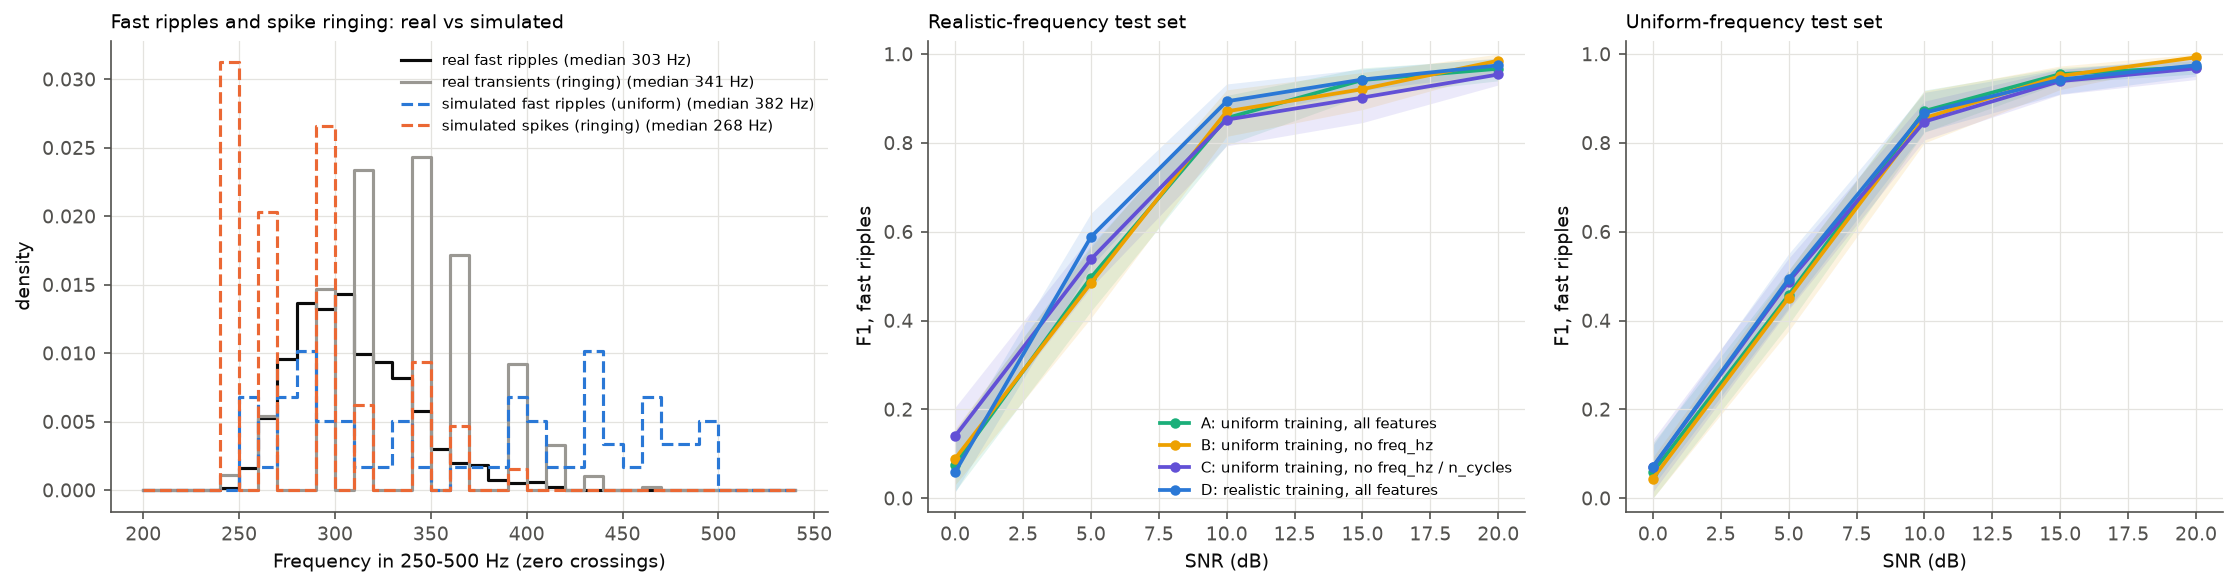

In [8]:
display(Image(filename=str(F / "ml_frequency_check.png")))

* Removing `freq_hz` (B), or `freq_hz` and `n_cycles` (C), or training on realistic frequencies (D) does not change the F1 on realistic test data: **the ML detector does not depend on the frequency artefact**. Other features carry the same information.
* The artefact is real, though: simulated spikes ring lower (median 268 Hz) than real transients (341 Hz), the opposite of the real ordering with respect to fast ripples (303 Hz).

## 4. Real data: leave-one-patient-out

In [9]:
summary = pd.read_csv(R / "real_lopo_summary.csv")
keep = ["macro_f1", "macro_recall", "macro_precision", "micro_f1", "fp_per_min_no_fr_patients"]
t = fmt(summary[summary.metric.isin(keep)])
t.pivot_table(index=["analysis", "strategy", "detector"], columns="metric", values="value", aggfunc="first")[keep]

metric                                        macro_f1       macro_recall    macro_precision           micro_f1 fp_per_min_no_fr_patients
analysis          strategy detector                                                                                                      
QC-clean channels A        energy    0.20 [0.09, 0.32]  0.28 [0.13, 0.45]  0.18 [0.08, 0.29]  0.53 [0.19, 0.68]         0.30 [0.00, 0.97]
                           ml        0.25 [0.12, 0.39]  0.28 [0.14, 0.44]  0.35 [0.21, 0.50]  0.61 [0.37, 0.71]         0.00 [0.00, 0.00]
                           wavelet   0.12 [0.06, 0.19]  0.12 [0.06, 0.20]  0.15 [0.07, 0.25]  0.31 [0.16, 0.35]         0.06 [0.00, 0.16]
                  B        energy    0.18 [0.11, 0.26]  0.80 [0.68, 0.91]  0.11 [0.06, 0.17]  0.27 [0.12, 0.45]         0.69 [0.41, 1.78]
                           ml        0.14 [0.08, 0.21]  0.63 [0.47, 0.77]  0.09 [0.05, 0.14]  0.22 [0.10, 0.36]         1.55 [0.55, 1.91]
                           wavelet   0.09 [0.05, 0.14]  0.55 [0.40, 0.69]  0.06 [0.03, 0.09]  0.11 [0.05, 0.19]         1.52 [0.27, 3.23]
all channels      A        energy    0.19 [0.09, 0.32]  0.28 [0.13, 0.45]  0.17 [0.08, 0.29]  0.52 [0.19, 0.68]         0.30 [0.00, 0.97]
                           ml        0.25 [0.12, 0.39]  0.28 [0.14, 0.44]  0.35 [0.21, 0.50]  0.61 [0.37, 0.71]         0.00 [0.00, 0.00]
                           wavelet   0.11 [0.06, 0.19]  0.12 [0.06, 0.20]  0.15 [0.07, 0.24]  0.30 [0.16, 0.35]         0.06 [0.00, 0.16]
                  B        energy    0.18 [0.11, 0.26]  0.80 [0.68, 0.91]  0.11 [0.06, 0.17]  0.27 [0.12, 0.45]         0.69 [0.41, 1.78]
                           ml        0.14 [0.08, 0.21]  0.63 [0.47, 0.77]  0.09 [0.05, 0.14]  0.22 [0.10, 0.36]         1.55 [0.55, 1.91]
                           wavelet   0.09 [0.05, 0.14]  0.55 [0.40, 0.69]  0.06 [0.03, 0.09]  0.11 [0.04, 0.19]         1.52 [0.27, 3.23]

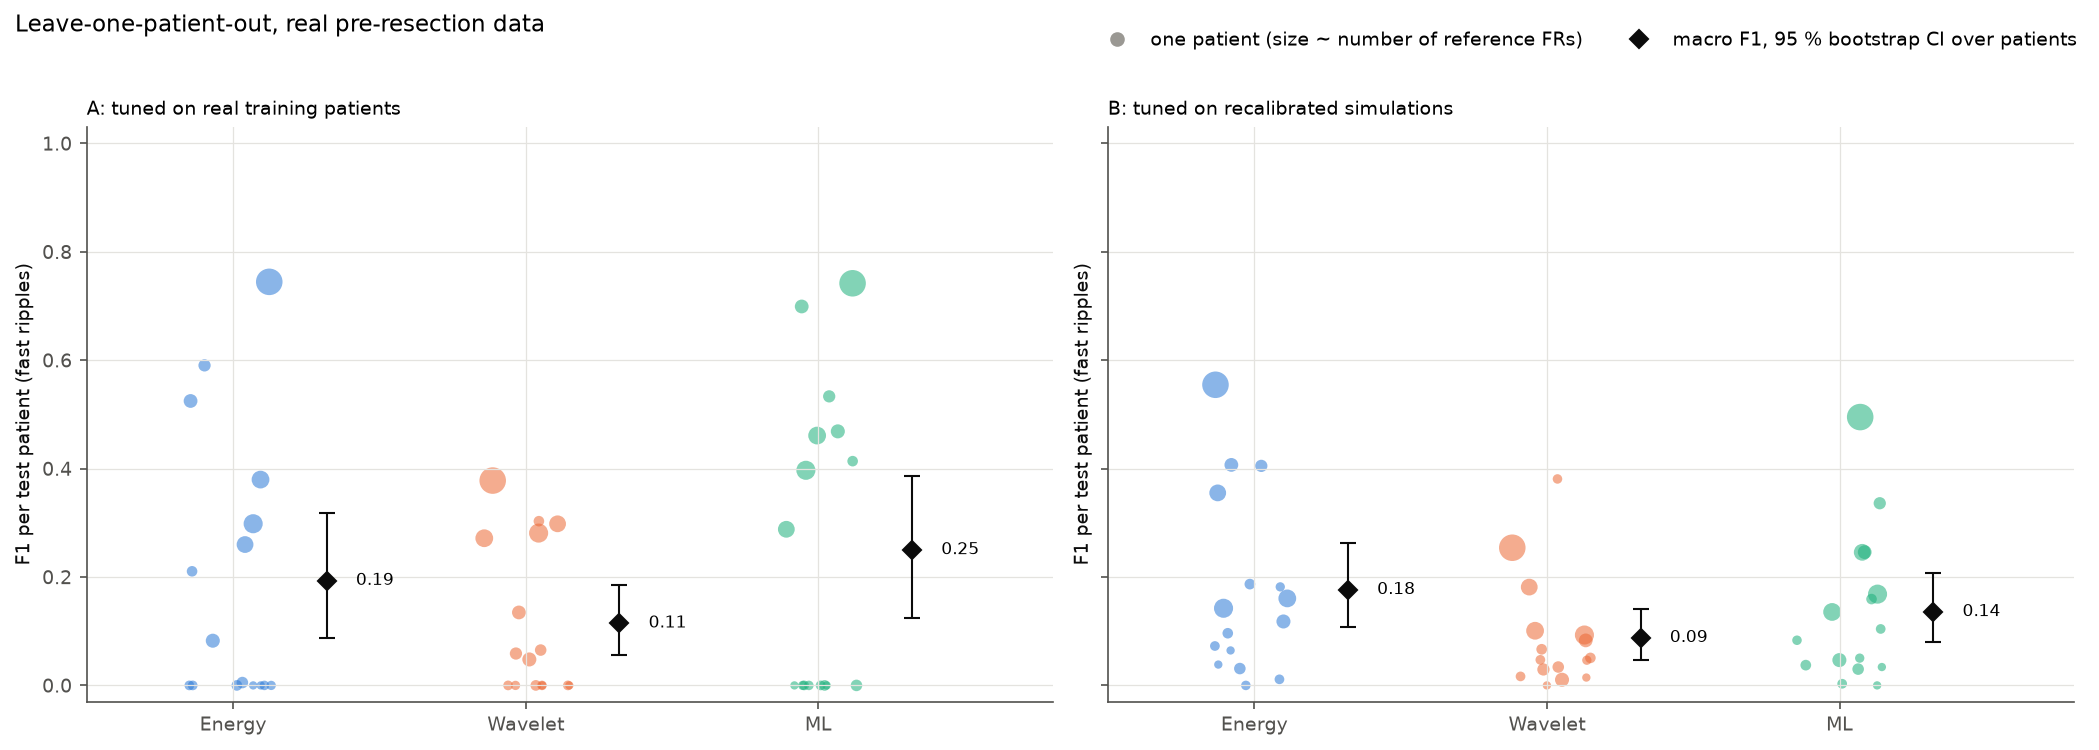

In [10]:
display(Image(filename=str(F / "real_lopo.png")))

### 4.1 Per patient (strategy A, all channels)

In [11]:
a = per_patient[(per_patient.analysis == "all channels") & (per_patient.strategy == "A")]
a.pivot_table(index=["patient", "n_ref"], columns="detector", values="f1").round(2)

,detector,energy,ml,wavelet
patient,n_ref,,,
01,175,0.26,0.29,0.30
02,70,0.08,0.47,0.05
03,6,0.00,0.00,0.00
04,63,0.52,0.70,0.13
05,231,0.38,0.46,0.27
06,1413,0.74,0.74,0.38
07,22,0.01,0.00,0.07
08,324,0.30,0.40,0.28
09,13,0.00,0.00,0.00


### 4.2 How many real fast ripples ride on a spike?

In [12]:
pd.read_csv(R / "real_fr_context.csv", dtype={"patient": str}).round(2)

,patient,n_fr,n_on_transient,fraction_on_transient
0,01,175,14,0.08
1,02,70,1,0.01
2,03,6,0,0.00
3,04,63,42,0.67
4,05,231,209,0.90
5,06,1413,1109,0.78
6,07,22,0,0.00
7,08,324,66,0.20
8,09,13,0,0.00
9,10,4,4,1.00


### 4.3 Leakage through the simulator calibration

Parameters recomputed without each test patient (strategy B uses them):

In [13]:
cal = pd.read_csv(R / "real_fold_calibration.csv", dtype={"left_out": str})
folds = cal.iloc[1:].drop(columns="left_out")
pd.DataFrame({"all patients": cal.iloc[0, 1:], "min over folds": folds.min(), "max over folds": folds.max()})

,all patients,min over folds,max over folds
beta,3.4776,3.4473,3.5121
crossover_hz,260.4736,254.4373,265.4901
beta_low,2.5603,2.5098,2.6091
std_uv,135.3767,123.3809,141.9350
apex_low_ms,1.1000,1.0000,1.1000
apex_high_ms,1.6000,1.6000,1.8000


## 5. Take-aways

* On simulations, the ML detector has the best fast-ripple F1 from 10 dB; the wavelet detector is the most precise but misses HFOs on spikes; the energy detector is fooled by spikes.
* On real data, with thresholds tuned on the other patients, the ML detector has the best macro F1 (0.25 [0.12, 0.39]), ahead of energy (0.19) and wavelet (0.12). The wavelet detector suffers most because 62 % of real fast ripples ride on a transient.
* Pooled (micro) F1 is 2-3 times higher than macro F1: performance is driven by a few FR-rich patients, and all detectors fail on the 7 patients with 1-13 reference FRs.
* Thresholds tuned on simulations are far too permissive on real data: the simulator underestimates real fast-ripple-band transients. Calibration leakage is negligible (parameters change by 1-8 % without the test patient).